# World Happiness Analysis (2015–2019)

**Project type:** Exploratory Data Analysis (EDA)  
**Tools:** Python, Pandas, NumPy, Matplotlib  
**Dataset:** Kaggle — World Happiness Report dataset (`unsdsn/world-happiness`)

## Project objective
Explore Happiness Scores across countries from 2015 to 2019, identify the highest- and lowest-scoring countries each year, and examine Morocco's score and selected indicators.

## Questions
1. What does the dataset look like, and does it contain missing or duplicate records?
2. Which countries have the highest and lowest Happiness Scores in each year?
3. How did Morocco's Happiness Score change from 2015 to 2019?
4. How does Morocco compare with the yearly average in this dataset?
5. Which indicators are correlated with Happiness Score in the 2019 cross-section?

## Important caveats
- The reports' indicators, labels, and methodologies may differ across years, so trends across editions should be interpreted cautiously.
- Correlation does not establish causation.
- Correlations calculated using Morocco's five yearly observations are exploratory only and are too fragile for strong conclusions.

## 1. Setup and load the data

In [1]:
!pip install -q kagglehub

import os
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("default")

path = kagglehub.dataset_download("unsdsn/world-happiness")
print("Dataset folder:", path)
print("Available files:", sorted(os.listdir(path)))

Using Colab cache for faster access to the 'world-happiness' dataset.
Dataset folder: /kaggle/input/world-happiness
Available files: ['2015.csv', '2016.csv', '2017.csv', '2018.csv', '2019.csv']


## 2. Explore the 2019 dataset

In [2]:
df = pd.read_csv(os.path.join(path, "2019.csv"))

display(df.head())
print("Dataset shape:", df.shape)
df.info()

,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
0,1,Finland,7.769,1.340,1.587,0.986,0.596,0.153,0.393
1,2,Denmark,7.600,1.383,1.573,0.996,0.592,0.252,0.410
2,3,Norway,7.554,1.488,1.582,1.028,0.603,0.271,0.341
3,4,Iceland,7.494,1.380,1.624,1.026,0.591,0.354,0.118
4,5,Netherlands,7.488,1.396,1.522,0.999,0.557,0.322,0.298


Dataset shape: (156, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156 entries, 0 to 155
Data columns (total 9 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Overall rank                  156 non-null    int64  
 1   Country or region             156 non-null    object 
 2   Score                         156 non-null    float64
 3   GDP per capita                156 non-null    float64
 4   Social support                156 non-null    float64
 5   Healthy life expectancy       156 non-null    float64
 6   Freedom to make life choices  156 non-null    float64
 7   Generosity                    156 non-null    float64
 8   Perceptions of corruption     156 non-null    float64
dtypes: float64(7), int64(1), object(1)
memory usage: 11.1+ KB


In [3]:
display(df.describe())

print("Missing values by column:")
display(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())
print(
    "Duplicate country names:",
    df["Country or region"].duplicated().sum()
)

,Overall rank,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
count,156.000000,156.000000,156.000000,156.000000,156.000000,156.000000,156.000000,156.000000
mean,78.500000,5.407096,0.905147,1.208814,0.725244,0.392571,0.184846,0.110603
std,45.177428,1.113120,0.398389,0.299191,0.242124,0.143289,0.095254,0.094538
min,1.000000,2.853000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,39.750000,4.544500,0.602750,1.055750,0.547750,0.308000,0.108750,0.047000
50%,78.500000,5.379500,0.960000,1.271500,0.789000,0.417000,0.177500,0.085500
75%,117.250000,6.184500,1.232500,1.452500,0.881750,0.507250,0.248250,0.141250
max,156.000000,7.769000,1.684000,1.624000,1.141000,0.631000,0.566000,0.453000


Missing values by column:


,0
Overall rank,0
Country or region,0
Score,0
GDP per capita,0
Social support,0
Healthy life expectancy,0
Freedom to make life choices,0
Generosity,0
Perceptions of corruption,0


Duplicate rows: 0
Duplicate country names: 0


## 3. Highest- and lowest-scoring countries in 2019

In [4]:
happiest_2019 = df.nlargest(10, "Score")
lowest_2019 = df.nsmallest(10, "Score")

display(happiest_2019[["Overall rank", "Country or region", "Score"]])
display(lowest_2019[["Overall rank", "Country or region", "Score"]])

,Overall rank,Country or region,Score
0,1,Finland,7.769
1,2,Denmark,7.600
2,3,Norway,7.554
3,4,Iceland,7.494
4,5,Netherlands,7.488
5,6,Switzerland,7.480
6,7,Sweden,7.343
7,8,New Zealand,7.307
8,9,Canada,7.278
9,10,Austria,7.246


,Overall rank,Country or region,Score
155,156,South Sudan,2.853
154,155,Central African Republic,3.083
153,154,Afghanistan,3.203
152,153,Tanzania,3.231
151,152,Rwanda,3.334
150,151,Yemen,3.380
149,150,Malawi,3.410
148,149,Syria,3.462
147,148,Botswana,3.488
146,147,Haiti,3.597


## 4. Morocco compared with the 2019 average

In [5]:
morocco_2019 = df.loc[df["Country or region"] == "Morocco"].copy()

if morocco_2019.empty:
    raise ValueError("Morocco was not found in the 2019 dataset.")

morocco_score = morocco_2019["Score"].iloc[0]
global_average_2019 = df["Score"].mean()
difference_2019 = morocco_score - global_average_2019

print("Morocco score:", round(morocco_score, 3))
print("2019 country-average score:", round(global_average_2019, 3))
print("Morocco minus average:", round(difference_2019, 3))

Morocco score: 5.208
2019 country-average score: 5.407
Morocco minus average: -0.199


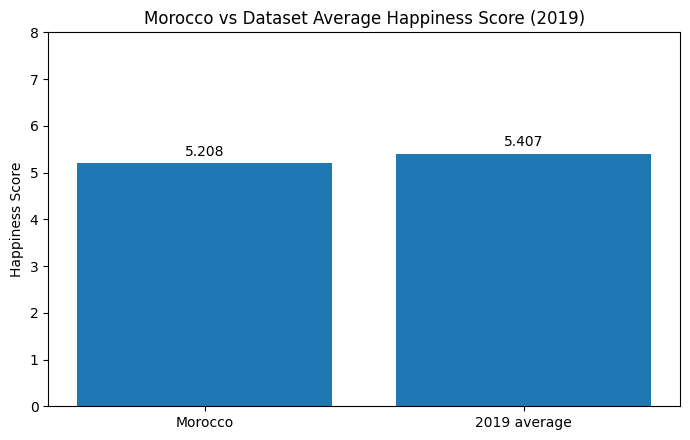

In [6]:
labels = ["Morocco", "2019 average"]
scores = [morocco_score, global_average_2019]

plt.figure(figsize=(7, 4.5))
bars = plt.bar(labels, scores)
plt.title("Morocco vs Dataset Average Happiness Score (2019)")
plt.ylabel("Happiness Score")
plt.ylim(0, 8)
plt.bar_label(bars, fmt="%.3f", padding=3)
plt.tight_layout()
plt.show()

### Top 10 countries vs Morocco

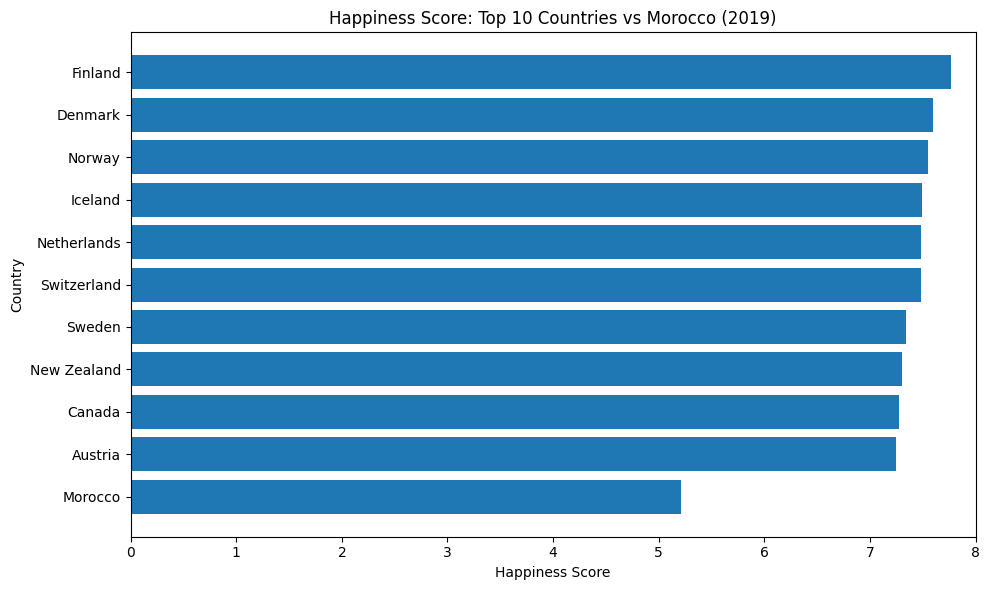

In [7]:
top_10_2019 = df.nlargest(10, "Score")
comparison_2019 = pd.concat([top_10_2019, morocco_2019], ignore_index=True)
comparison_2019 = comparison_2019.sort_values("Score", ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(comparison_2019["Country or region"], comparison_2019["Score"])
plt.title("Happiness Score: Top 10 Countries vs Morocco (2019)")
plt.xlabel("Happiness Score")
plt.ylabel("Country")
plt.xlim(0, 8)
plt.tight_layout()
plt.show()

## 5. Relationships between indicators and Happiness Score (2019)

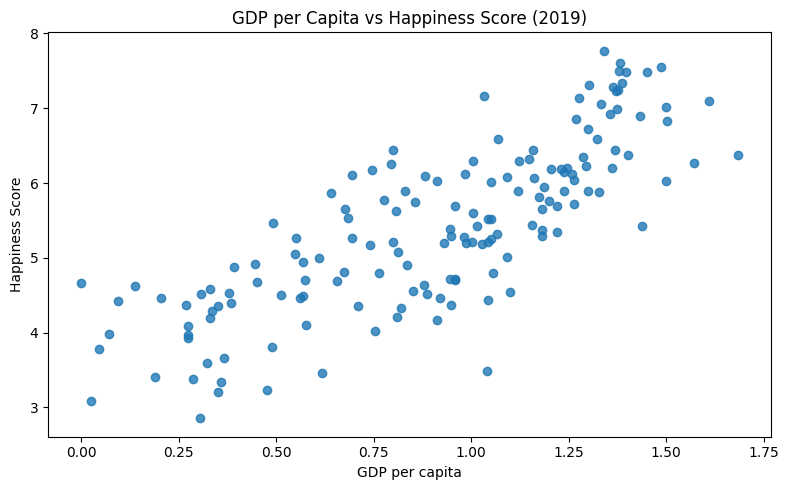

Pearson correlation (GDP per capita, Score): 0.794


In [8]:
plt.figure(figsize=(8, 5))
plt.scatter(df["GDP per capita"], df["Score"], alpha=0.8)
plt.title("GDP per Capita vs Happiness Score (2019)")
plt.xlabel("GDP per capita")
plt.ylabel("Happiness Score")
plt.tight_layout()
plt.show()

gdp_correlation_2019 = df["GDP per capita"].corr(df["Score"])
print("Pearson correlation (GDP per capita, Score):", round(gdp_correlation_2019, 3))

,Score
GDP per capita,0.794
Healthy life expectancy,0.780
Social support,0.777
Freedom to make life choices,0.567
Perceptions of corruption,0.386
Generosity,0.076


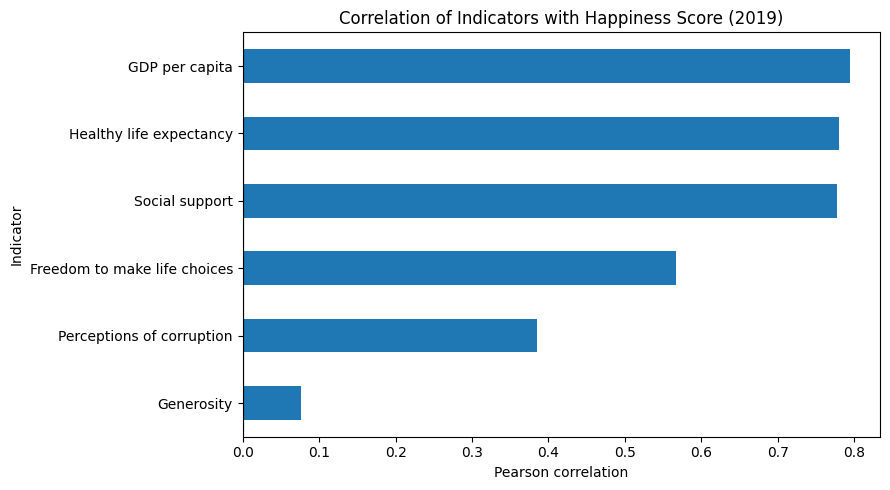

In [9]:
correlations_2019 = (
    df.corr(numeric_only=True)["Score"]
    .drop(["Score", "Overall rank"], errors="ignore")
    .sort_values(ascending=False)
)

display(correlations_2019.round(3))

plt.figure(figsize=(9, 5))
correlations_2019.sort_values().plot(kind="barh")
plt.title("Correlation of Indicators with Happiness Score (2019)")
plt.xlabel("Pearson correlation")
plt.ylabel("Indicator")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

**Interpretation note:** These are associations across countries in the 2019 dataset. They do not prove that any indicator causes happiness. The corruption indicator's direction also needs careful interpretation based on the source's definition.

## 6. Morocco compared with 2019 indicator averages

In [10]:
factors_2019 = [
    "GDP per capita",
    "Social support",
    "Healthy life expectancy",
    "Freedom to make life choices",
    "Generosity",
    "Perceptions of corruption",
]

morocco_indicator_comparison = pd.DataFrame({
    "Indicator": factors_2019,
    "Morocco": [morocco_2019[f].iloc[0] for f in factors_2019],
    "Dataset average": [df[f].mean() for f in factors_2019],
})

display(morocco_indicator_comparison.round(3))

,Indicator,Morocco,Dataset average
0,GDP per capita,0.801,0.905
1,Social support,0.782,1.209
2,Healthy life expectancy,0.782,0.725
3,Freedom to make life choices,0.418,0.393
4,Generosity,0.036,0.185
5,Perceptions of corruption,0.076,0.111


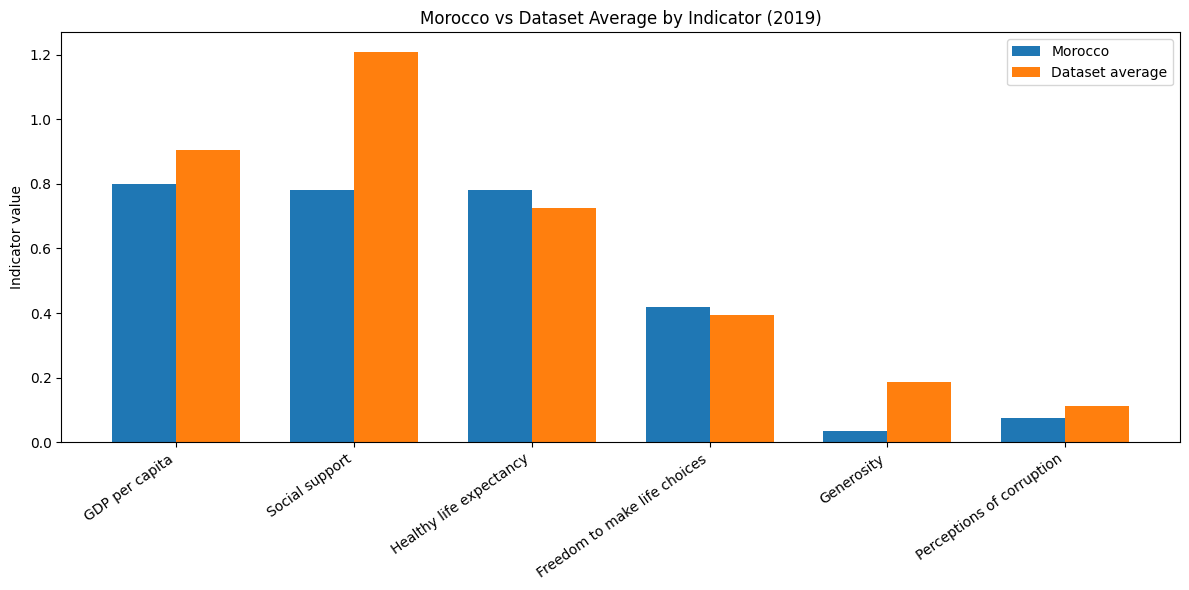

In [11]:
x = np.arange(len(factors_2019))
width = 0.36

fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(x - width / 2, morocco_indicator_comparison["Morocco"], width, label="Morocco")
ax.bar(x + width / 2, morocco_indicator_comparison["Dataset average"], width, label="Dataset average")
ax.set_title("Morocco vs Dataset Average by Indicator (2019)")
ax.set_ylabel("Indicator value")
ax.set_xticks(x)
ax.set_xticklabels(factors_2019, rotation=35, ha="right")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Prepare a consistent multi-year dataset (2015–2019)

In [12]:
years = [2015, 2016, 2017, 2018, 2019]
dataframes = []

column_mapping = {
    "Country or region": "Country",
    "Overall rank": "Happiness Rank",
    "Happiness.Rank": "Happiness Rank",
    "Happiness Rank": "Happiness Rank",
    "Score": "Happiness Score",
    "Happiness.Score": "Happiness Score",
    "Economy (GDP per Capita)": "GDP per capita",
    "Economy..GDP.per.Capita.": "GDP per capita",
    "Family": "Social support",
    "Health (Life Expectancy)": "Healthy life expectancy",
    "Health..Life.Expectancy.": "Healthy life expectancy",
    "Freedom": "Freedom to make life choices",
    "Trust (Government Corruption)": "Perceptions of corruption",
    "Trust..Government.Corruption.": "Perceptions of corruption",
}

common_columns = [
    "Country", "Year", "Happiness Rank", "Happiness Score",
    "GDP per capita", "Social support", "Healthy life expectancy",
    "Freedom to make life choices", "Generosity", "Perceptions of corruption"
]

for year in years:
    temp_df = pd.read_csv(os.path.join(path, f"{year}.csv"))
    temp_df = temp_df.rename(columns=column_mapping)
    temp_df["Year"] = year

    available_columns = [col for col in common_columns if col in temp_df.columns]
    clean_df = temp_df[available_columns].copy()
    dataframes.append(clean_df)

happiness_df = pd.concat(dataframes, ignore_index=True)

print("Combined dataset shape:", happiness_df.shape)
display(happiness_df.head())
display(happiness_df.groupby("Year").size().rename("Rows per year"))

Combined dataset shape: (782, 10)


,Country,Year,Happiness Rank,Happiness Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
0,Switzerland,2015,1,7.587,1.39651,1.34951,0.94143,0.66557,0.29678,0.41978
1,Iceland,2015,2,7.561,1.30232,1.40223,0.94784,0.62877,0.43630,0.14145
2,Denmark,2015,3,7.527,1.32548,1.36058,0.87464,0.64938,0.34139,0.48357
3,Norway,2015,4,7.522,1.45900,1.33095,0.88521,0.66973,0.34699,0.36503
4,Canada,2015,5,7.427,1.32629,1.32261,0.90563,0.63297,0.45811,0.32957


,Rows per year
Year,
2015,158
2016,157
2017,155
2018,156
2019,156


## 8. Data quality checks

In [13]:
missing_counts = happiness_df.isnull().sum()
missing_percent = (happiness_df.isnull().mean() * 100).sort_values(ascending=False)

print("Missing values by column:")
display(missing_counts)

print("Missing-value percentage:")
display(missing_percent.round(3))

print("Duplicate rows:", happiness_df.duplicated().sum())
print(
    "Duplicate country-year pairs:",
    happiness_df.duplicated(subset=["Country", "Year"]).sum()
)

print("Data types:")
display(happiness_df.dtypes)

Missing values by column:


,0
Country,0
Year,0
Happiness Rank,0
Happiness Score,0
GDP per capita,0
Social support,0
Healthy life expectancy,0
Freedom to make life choices,0
Generosity,0
Perceptions of corruption,1


Missing-value percentage:


,0
Perceptions of corruption,0.128
Country,0.000
Year,0.000
Happiness Rank,0.000
GDP per capita,0.000
Happiness Score,0.000
Social support,0.000
Healthy life expectancy,0.000
Freedom to make life choices,0.000
Generosity,0.000


Duplicate rows: 0
Duplicate country-year pairs: 0
Data types:


,0
Country,object
Year,int64
Happiness Rank,int64
Happiness Score,float64
GDP per capita,float64
Social support,float64
Healthy life expectancy,float64
Freedom to make life choices,float64
Generosity,float64
Perceptions of corruption,float64


The combined dataset contains one missing value in `Perceptions of corruption` (United Arab Emirates, 2018 in the source file). It is left as missing rather than replaced with an unsupported estimate. Pandas correlation calculations use available paired observations.

## 9. Morocco's Happiness Score trend

In [14]:
morocco_trend = (
    happiness_df[happiness_df["Country"] == "Morocco"]
    .sort_values("Year")
    .copy()
)

display(morocco_trend[["Year", "Happiness Rank", "Happiness Score"]])

,Year,Happiness Rank,Happiness Score
91,2015,92,5.013
247,2016,90,5.151
398,2017,84,5.235
554,2018,85,5.254
714,2019,89,5.208


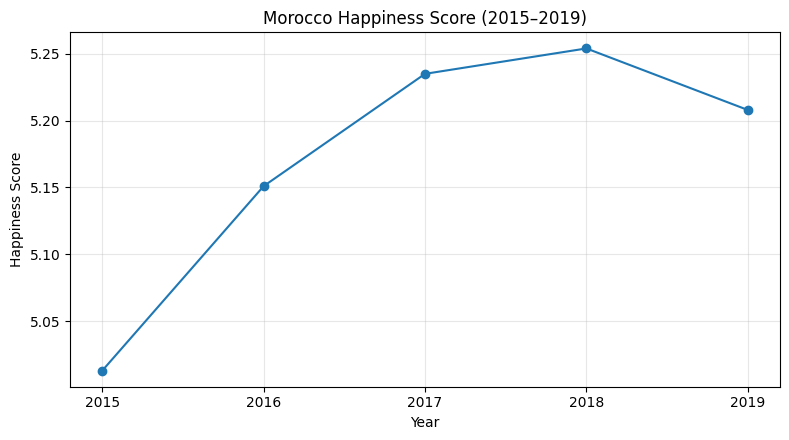

In [15]:
plt.figure(figsize=(8, 4.5))
plt.plot(morocco_trend["Year"], morocco_trend["Happiness Score"], marker="o")
plt.title("Morocco Happiness Score (2015–2019)")
plt.xlabel("Year")
plt.ylabel("Happiness Score")
plt.xticks(morocco_trend["Year"])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Morocco vs the average of listed countries by year

In [16]:
global_trend = (
    happiness_df.groupby("Year")["Happiness Score"]
    .mean()
    .reset_index(name="Dataset average")
)

morocco_vs_global = morocco_trend[["Year", "Happiness Score"]].merge(
    global_trend, on="Year"
).rename(columns={"Happiness Score": "Morocco score"})

display(morocco_vs_global.round(3))

,Year,Morocco score,Dataset average
0,2015,5.013,5.376
1,2016,5.151,5.382
2,2017,5.235,5.354
3,2018,5.254,5.376
4,2019,5.208,5.407


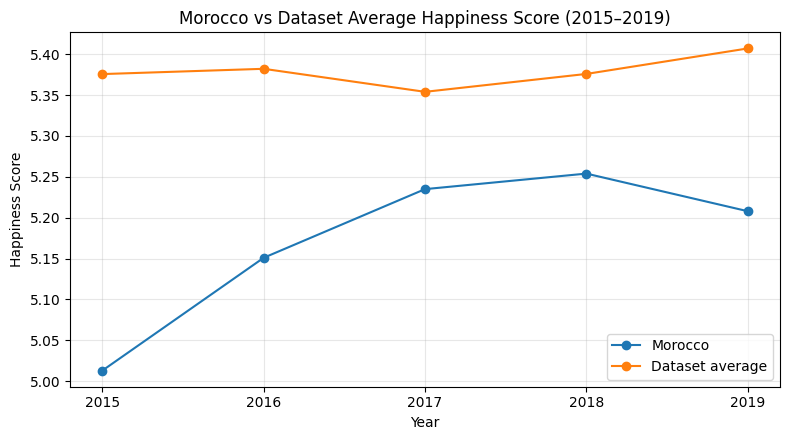

In [17]:
plt.figure(figsize=(8, 4.5))
plt.plot(morocco_vs_global["Year"], morocco_vs_global["Morocco score"], marker="o", label="Morocco")
plt.plot(morocco_vs_global["Year"], morocco_vs_global["Dataset average"], marker="o", label="Dataset average")
plt.title("Morocco vs Dataset Average Happiness Score (2015–2019)")
plt.xlabel("Year")
plt.ylabel("Happiness Score")
plt.xticks(morocco_vs_global["Year"])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 11. Exploratory correlations for Morocco

In [18]:
morocco_factors = morocco_trend.copy()

morocco_factor_columns = [
    "GDP per capita",
    "Social support",
    "Healthy life expectancy",
    "Freedom to make life choices",
    "Generosity",
    "Perceptions of corruption",
]

display(morocco_factors[["Year", "Happiness Score"] + morocco_factor_columns])

,Year,Happiness Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
91,2015,5.013,0.734790,0.640950,0.609540,0.416910,0.07172,0.085460
247,2016,5.151,0.840580,0.385950,0.594710,0.256460,0.04053,0.084040
398,2017,5.235,0.878115,0.774864,0.597711,0.408158,0.03221,0.087763
554,2018,5.254,0.779000,0.797000,0.669000,0.460000,0.02600,0.074000
714,2019,5.208,0.801000,0.782000,0.782000,0.418000,0.03600,0.076000


,Happiness Score
GDP per capita,0.594
Social support,0.468
Healthy life expectancy,0.344
Freedom to make life choices,0.211
Perceptions of corruption,-0.466
Generosity,-0.988


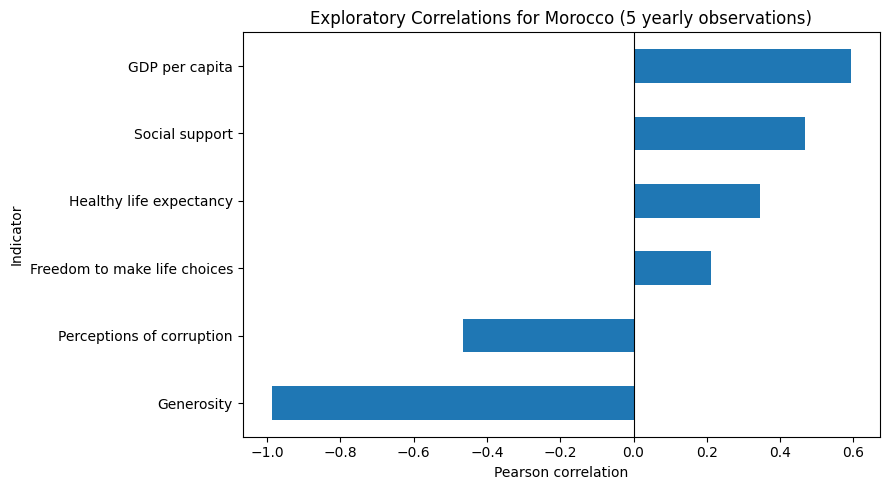

In [19]:
morocco_correlations = (
    morocco_factors[["Happiness Score"] + morocco_factor_columns]
    .corr()["Happiness Score"]
    .drop("Happiness Score")
    .sort_values(ascending=False)
)

display(morocco_correlations.round(3))

plt.figure(figsize=(9, 5))
morocco_correlations.sort_values().plot(kind="barh")
plt.title("Exploratory Correlations for Morocco (5 yearly observations)")
plt.xlabel("Pearson correlation")
plt.ylabel("Indicator")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

**Important limitation:** Morocco has only five yearly observations here. These correlations are highly sensitive to individual values and should not be used to claim that a factor causes happiness or to make strong claims about the relationship.

## 12. Highest and lowest Happiness Score by year

In [20]:
yearly_top = happiness_df.loc[
    happiness_df.groupby("Year")["Happiness Score"].idxmax(),
    ["Year", "Country", "Happiness Score"]
].sort_values("Year").rename(columns={
    "Country": "Country highest",
    "Happiness Score": "Score highest",
})

yearly_bottom = happiness_df.loc[
    happiness_df.groupby("Year")["Happiness Score"].idxmin(),
    ["Year", "Country", "Happiness Score"]
].sort_values("Year").rename(columns={
    "Country": "Country lowest",
    "Happiness Score": "Score lowest",
})

yearly_comparison = yearly_top.merge(yearly_bottom, on="Year")
yearly_comparison["Score gap"] = (
    yearly_comparison["Score highest"] - yearly_comparison["Score lowest"]
)

display(yearly_comparison.round({"Score highest": 3, "Score lowest": 3, "Score gap": 3}))

,Year,Country highest,Score highest,Country lowest,Score lowest,Score gap
0,2015,Switzerland,7.587,Togo,2.839,4.748
1,2016,Denmark,7.526,Burundi,2.905,4.621
2,2017,Norway,7.537,Central African Republic,2.693,4.844
3,2018,Finland,7.632,Burundi,2.905,4.727
4,2019,Finland,7.769,South Sudan,2.853,4.916


## 13. Key findings

- Morocco's Happiness Score increased from **5.013 in 2015** to **5.254 in 2018**, then decreased to **5.208 in 2019**.
- Morocco's score was below the average score of the countries listed in each annual dataset from 2015 to 2019.
- Finland had the highest score in both 2018 and 2019 in this dataset.
- The gap between the highest and lowest country scores was greater than 4.6 points in every year.
- In the 2019 cross-country data, GDP per capita had a positive correlation with Happiness Score. This is an association, not proof of causation.

## 14. Limitations

- Country coverage varies by year, and report methodology or indicator definitions may change across editions.
- The annual mean is an unweighted average of the countries listed in that year's file, not a population-weighted global average.
- The Morocco-only correlation analysis uses just five observations and is not statistically robust.
- Some indicators may not be directly comparable across every report edition because of differences in naming, measurement, or methodology.
- The dataset is observational; correlations do not establish cause and effect.

## 15. Conclusion and next steps

This project demonstrates data loading, cleaning, combining multi-year datasets, exploratory analysis, visualization, and cautious interpretation of correlations using Python, Pandas, NumPy, and Matplotlib.

**Possible next steps:** investigate differences between regions using a consistently defined subset of indicators, document the source and data dictionary, and create a separate machine-learning project with a clear prediction target and evaluation plan.